In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 4a First, assume linear wave theory

In [ ]:
#input parameters
g = 9.81
h = 8                   # Water depth [m]
N = 100                 # Number of wave components
f_min = 1 / maxT
f_max = 1 / minT
dt = 0.05
T = 100                 # Simulation duration [s]
Hs = 8                  # Valid ???
Tp = 12                 # Given range
fp = 1 / Tp


In [ ]:
#Get the jonhson spectrum from Q3


In [ ]:
eta_t 

In [10]:
print(3.6 * np.sqrt(8))
print(5 * np.sqrt(8))

10.182337649086286
14.142135623730951


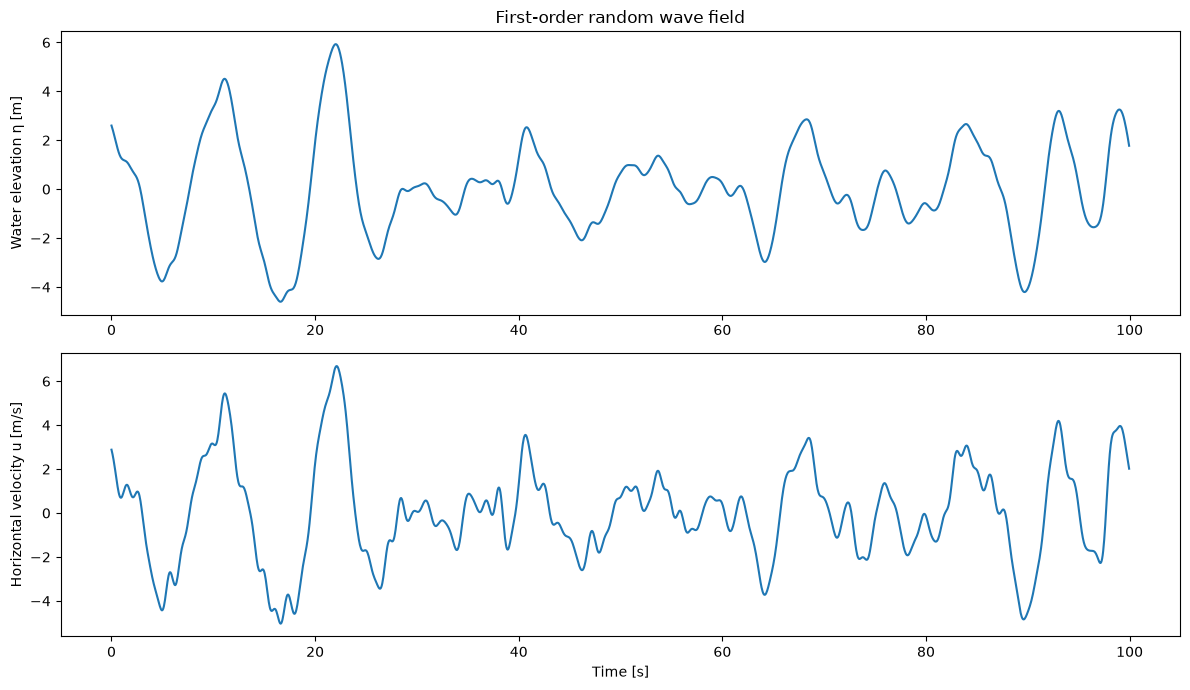

0.027651218539380493
1.995735967859733
12.76571034647151


In [113]:
# Specifying frequency range
minT = 1 # 1second
maxT = 30 # 30 seconds

# Parameters
g = 9.81
h = 10                  # Water depth [m]
N = 100                 # Number of wave components
f_min = 1 / maxT
f_max = 1 / minT
dt = 0.05
T = 100                 # Simulation duration [s]
Hs = 8                  # Valid ???
Tp = 12                 # Given range
fp = 1 / Tp

# Frequency discretization
f = np.linspace(f_min, f_max, N)
df = f[1] - f[0]
omega = 2 * np.pi * f

# Random phases
np.random.seed(42)
phi = np.random.uniform(0, 2*np.pi, N)

# Example wave spectrum (replace with JONSWAP if required)
def S(f):
    return 5/16 * Hs**2 * f ** (-5) * fp**4 * np.exp(-5/4 * (fp/f)**4)

# Wave amplitudes
a = np.sqrt(2 * S(f) * df)

# Solve dispersion relation for each frequency
k = np.zeros(N)

for i in range(N):
    ki = omega[i]**2 / g
    for _ in range(100):
        ki = ki - (
            g * ki * np.tanh(ki*h) - omega[i]**2
        ) / (
            g * (np.tanh(ki*h) + ki*h/np.cosh(ki*h)**2)
        )
    k[i] = ki

# Time vector
t = np.arange(0, T, dt)

# First-order wave field
eta = np.zeros(len(t))
u = np.zeros(len(t))
acheck = 0

for i in range(N):
    phase = omega[i]*t + phi[i]

    eta += a[i] * np.cos(phase)

    u += (
        a[i] * omega[i] *
        np.cosh(k[i]*h) / np.sinh(k[i]*h)
        * np.cos(phase)
    )

    acheck += a[i]

# Plot
fig, ax = plt.subplots(2, 1, figsize=(12, 7))

ax[0].plot(t, eta)
ax[0].set_ylabel("Water elevation η [m]")
ax[0].set_title("First-order random wave field")

ax[1].plot(t, u)
ax[1].set_ylabel("Horizontal velocity u [m/s]")
ax[1].set_xlabel("Time [s]")

plt.tight_layout()
plt.show()
print(eta.mean())
print(eta.std())
print(acheck)

4.0
4.0
Standard deviation of random eta=1.9957, m0 (intended variance)=4.0
Mean of random eta=0.0277, intended mean=0


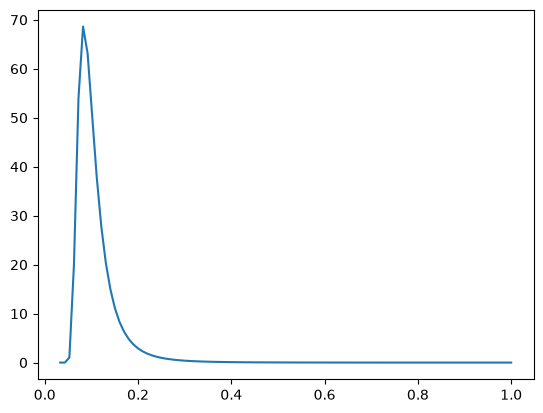

In [108]:
plt.plot(f, S(f));

from scipy.integrate import quad

m0, error = quad(S, 0, np.inf)

print(m0)
print(Hs**2 / 16)

print(f'Standard deviation of random eta={eta.std():.4f}, m0 (intended variance)={Hs**2 / 16}')
print(f'Mean of random eta={eta.mean():.4f}, intended mean=0')


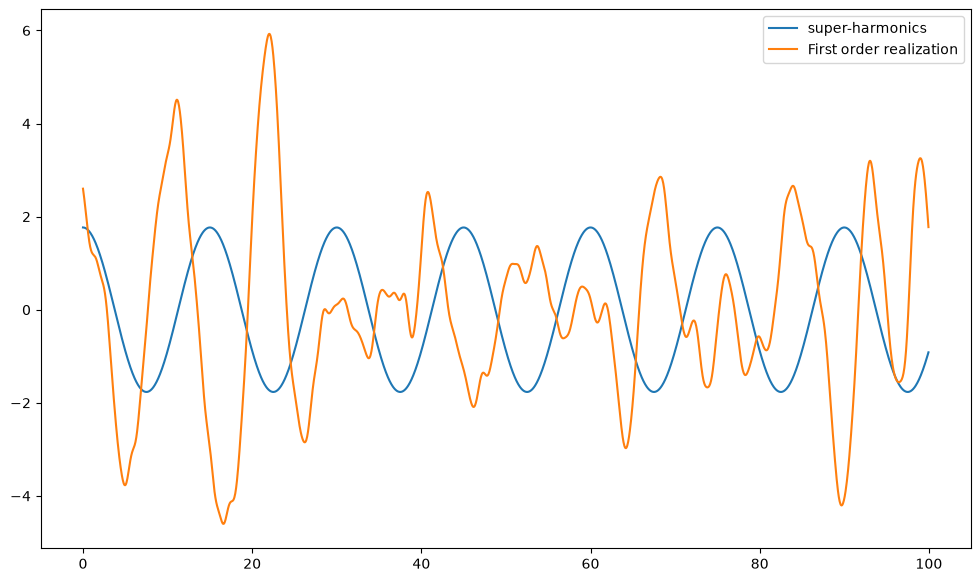

In [121]:
f = np.linspace(f_min, f_max, N)
superf = f * 2
subf = f / 2
case = 1

fn = [f, superf, subf]

# Frequency discretization
f = np.linspace(f_min, f_max, N)
df = fn[case][1] - fn[case][0]
omega = 2 * np.pi * fn[case]

# Random phases
np.random.seed(42)
phi = np.random.uniform(0, 2*np.pi, N)

# Example wave spectrum (replace with JONSWAP if required)
def S(f):
    return 5/16 * Hs**2 * f ** (-5) * fp**4 * np.exp(-5/4 * (fp/f)**4)

# Wave amplitudes
a = np.sqrt(2 * S(fn[case]) * df)


# Solve dispersion relation for each frequency
k = np.zeros(N)

for i in range(N):
    ki = omega[i]**2 / g
    for _ in range(100):
        ki = ki - (
            g * ki * np.tanh(ki*h) - omega[i]**2
        ) / (
            g * (np.tanh(ki*h) + ki*h/np.cosh(ki*h)**2)
        )
    k[i] = ki

H = 2 * a[0]

tsup = np.arange(0, T, dt)
etasup = H / 2 * np.cos(-omega[0]*t) + H**2 * k[0] / 16 * np.cosh(k[0]*h) / np.sinh(k[0]*h)**3 * (2 + np.cosh(2*k[0]*h)) * (np.cos(-omega[0]*t))

fig, ax = plt.subplots(1, 1, figsize=(12, 7))
plt.plot(tsup, etasup, label='super-harmonics')
plt.plot(t, eta, label='First order realization')
plt.legend();

##### Stuff

In [110]:
# # Top Floor Read
# data_top = pd.read_csv('top_floor_cleaned.csv')
# data_x3 = data_top.iloc[:, 2].to_numpy()
# data_y3 = data_top.iloc[:, 3].to_numpy()
# data_z3 = data_top.iloc[:, 4].to_numpy()

# # Second Floor Read
# data_2 = pd.read_csv('2nd_floor_cleaned.csv')
# data_x2 = data_2.iloc[:, 2].to_numpy()
# data_y2 = data_2.iloc[:, 3].to_numpy()
# data_z2 = data_2.iloc[:, 4].to_numpy()

# # First Floor Read
# data_1 = pd.read_csv('1st_floor_cleaned.csv')
# data_x1 = data_1.iloc[:, 2].to_numpy()
# data_y1 = data_1.iloc[:, 3].to_numpy()
# data_z1 = data_1.iloc[:, 4].to_numpy()

# # Ground Floor Read
# data_0 = pd.read_csv('ground_floor_cleaned.csv')
# data_x0 = data_0.iloc[:, 2].to_numpy()
# data_y0 = data_0.iloc[:, 3].to_numpy()
# data_z0 = data_0.iloc[:, 4].to_numpy()






data_top = pd.read_csv('top_floor_cleaned.csv')
data_x3 = data_top.iloc[:, 2].to_numpy()
data_y3 = data_top.iloc[:, 3].to_numpy()
data_z3 = data_top.iloc[:, 4].to_numpy()

# Second Floor Read
data_2 = pd.read_csv('2nd_floor_cleaned.csv')
data_x2 = data_2.iloc[:, 2].to_numpy()
data_y2 = data_2.iloc[:, 3].to_numpy()
data_z2 = data_2.iloc[:, 4].to_numpy()

# First Floor Read
data_1 = pd.read_csv('1st_floor_cleaned.csv')
data_x1 = data_1.iloc[:, 2].to_numpy()
data_y1 = data_1.iloc[:, 3].to_numpy()
data_z1 = data_1.iloc[:, 4].to_numpy()

# Ground Floor Read
data_0 = pd.read_csv('ground_floor_cleaned.csv')
data_x0 = data_0.iloc[:, 2].to_numpy()
data_y0 = data_0.iloc[:, 3].to_numpy()
data_z0 = data_0.iloc[:, 4].to_numpy()

Fs = 200  # 200 Hz - data sampling rate
Ts = 1 / Fs  # time interval

# Time columns (Note: t3 is preserved separately for the Power Spectrum calculation)
t3 = np.arange(0, len(data_x3)) * Ts
t2 = np.arange(0, len(data_x2)) * Ts
t1 = np.arange(0, len(data_x1)) * Ts
t0 = np.arange(0, len(data_x0)) * Ts

npts3 = len(data_x3)  # Top Floor
npts2 = len(data_x2)  # 2nd Floor
npts1 = len(data_x1)  # 1st Floor
npts0 = len(data_x0)  # Ground Floor


# Helper for MATLAB's 2^nextpow2(n)
def next_pow2(n):
    return int(2 ** np.ceil(np.log2(n)))


n3 = next_pow2(npts3)
n2 = next_pow2(npts2)
n1 = next_pow2(npts1)
n0 = next_pow2(npts0)

# FFT (Normalized with Fs to compare with SeismoSignal results)
FFT_data_x3 = np.fft.fft(data_x3, n3) / Fs
FFT_data_x2 = np.fft.fft(data_x2, n2) / Fs
FFT_data_x1 = np.fft.fft(data_x1, n1) / Fs
FFT_data_x0 = np.fft.fft(data_x0, n0) / Fs

freq3 = (Fs / 2) * np.linspace(0, 1, n3 // 2 + 1)
freq2 = (Fs / 2) * np.linspace(0, 1, n2 // 2 + 1)
freq1 = (Fs / 2) * np.linspace(0, 1, n1 // 2 + 1)
freq0 = (Fs / 2) * np.linspace(0, 1, n0 // 2 + 1)

FFT_data_x3 = np.abs(FFT_data_x3[: len(freq3)])
FFT_data_x2 = np.abs(FFT_data_x2[: len(freq2)])
FFT_data_x1 = np.abs(FFT_data_x1[: len(freq1)])
FFT_data_x0 = np.abs(FFT_data_x0[: len(freq0)])

# Figure 1: Fourier Amplitude Spectra
plt.figure(1)
plt.plot(freq3, FFT_data_x3, 'b', label='Top Floor')
plt.plot(freq2, FFT_data_x2, 'r', label='2nd Floor')
plt.plot(freq1, FFT_data_x1, 'y', label='1st Floor')
plt.plot(freq0, FFT_data_x0, 'g', label='Ground Floor')
plt.title('Fourier Amplitude Spectra')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Fourier Amplitude')
plt.legend()
plt.grid(True)

# Export FFT_x to Excel
df_fft = pd.DataFrame({'Frequency_Hz': freq3, 'FFT_Amplitude': FFT_data_x3})
df_fft.to_excel('FFT_x.xlsx', sheet_name='Sheet1', index=False, header=False)

# Power Spectrum - SeismoSignal
Arms_x = ((1 / np.max(t3)) * np.trapezoid(data_x3**2, t3)) ** 0.5
psd3 = (1 / (np.pi * (Arms_x**2) * np.max(t3))) * (FFT_data_x3**2)

# Figure 2: Power Spectra
plt.figure(2)
plt.plot(freq3, psd3)
plt.title('Power Spectra')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.grid(True)

# Export PSD_x to Sheet3 of Excel
df_psd = pd.DataFrame({'Frequency_Hz': freq3, 'PSD': psd3})
with pd.ExcelWriter('PSD_x.xlsx', engine='openpyxl') as writer:
    # Create empty placeholder sheets to match MATLAB's sheet index 3
    pd.DataFrame().to_excel(writer, sheet_name='Sheet1', index=False)
    pd.DataFrame().to_excel(writer, sheet_name='Sheet2', index=False)
    df_psd.to_excel(writer, sheet_name='Sheet3', index=False, header=False)

plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'top_floor_cleaned.csv'